# Classificador de imagens com CNN, versão 1 (Aulas 14 e 21)

Primeira rede convolucional: duas camadas `Conv2D` seguidas de `MaxPooling2D` e uma
camada densa de classificação, treinada no CIFAR-10 (60 mil imagens 32x32, 10 classes).

In [1]:
# Habilita a GPU: pré-carrega as bibliotecas CUDA do pacote nvidia antes de importar o TensorFlow.
import ctypes, glob, importlib.util, os
_pkg = os.path.dirname(importlib.util.find_spec("nvidia").submodule_search_locations[0])
for _lib in sorted(glob.glob(os.path.join(_pkg, "nvidia", "*", "lib", "*.so*"))):
    try:
        ctypes.CDLL(_lib, mode=ctypes.RTLD_GLOBAL)
    except OSError:
        pass
import tensorflow as tf
print("GPUs disponíveis:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1792895493.695745  290380 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


GPUs disponíveis: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

tf.keras.utils.set_random_seed(42)
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()
y_train_full, y_test = y_train_full.ravel(), y_test.ravel()

CLASSES = ["avião", "automóvel", "pássaro", "gato", "cervo", "cachorro", "sapo", "cavalo", "navio", "caminhão"]

X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Validação separada do treino, para acompanhar o overfitting sem tocar no teste.
X_train, X_val = X_train_full[:45000], X_train_full[45000:]
y_train, y_val = y_train_full[:45000], y_train_full[45000:]
print(X_train.shape, X_val.shape, X_test.shape)

(45000, 32, 32, 3) (5000, 32, 32, 3) (10000, 32, 32, 3)


## 1. Arquitetura

As convoluções extraem padrões locais (bordas, texturas); o pooling reduz a resolução.

In [3]:
model = tf.keras.Sequential(
    [
        tf.keras.Input(shape=(32, 32, 3)),
        tf.keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax"),
    ],
    name="cnn_v1",
)
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

I0000 00:00:1792895499.032583  290380 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4132 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "cnn_v1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 282,250 (1.08 MB)

 Trainable params: 282,250 (1.08 MB)

 Non-trainable params: 0 (0.00 B)

## 2. Treino

In [4]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=8,
    batch_size=64,
    verbose=0,
)

W0000 00:00:1792895501.206470  290380 cpu_allocator_impl.cc:82] Allocation of 552960000 exceeds 10% of free system memory.
W0000 00:00:1792895501.725338  290380 cpu_allocator_impl.cc:82] Allocation of 552960000 exceeds 10% of free system memory.


I0000 00:00:1792895502.628548  290607 service.cc:153] XLA service 0x7c95e8032070 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792895502.628567  290607 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792895502.676124  290607 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


I0000 00:00:1792895502.853239  290607 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1792895502.862735  290607 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1582__.30


I0000 00:00:1792895507.197137  290607 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


I0000 00:00:1792895508.856909  290607 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1582__.30


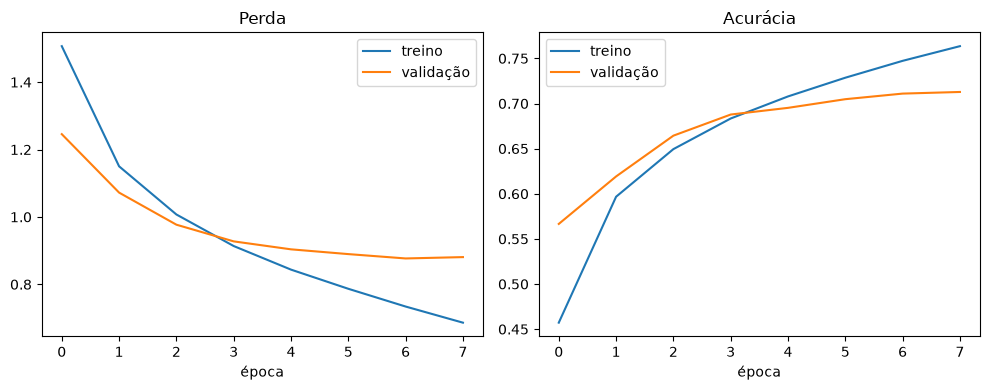

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history.history["loss"], label="treino")
axes[0].plot(history.history["val_loss"], label="validação")
axes[0].set_title("Perda")
axes[0].set_xlabel("época")
axes[0].legend()
axes[1].plot(history.history["accuracy"], label="treino")
axes[1].plot(history.history["val_accuracy"], label="validação")
axes[1].set_title("Acurácia")
axes[1].set_xlabel("época")
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. Avaliação no conjunto de teste

In [6]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Teste: perda={test_loss:.4f}  acurácia={test_accuracy:.4f}")

W0000 00:00:1792895526.189200  290380 cpu_allocator_impl.cc:82] Allocation of 122880000 exceeds 10% of free system memory.
W0000 00:00:1792895526.307588  290380 cpu_allocator_impl.cc:82] Allocation of 122880000 exceeds 10% of free system memory.


Teste: perda=0.9222  acurácia=0.6930


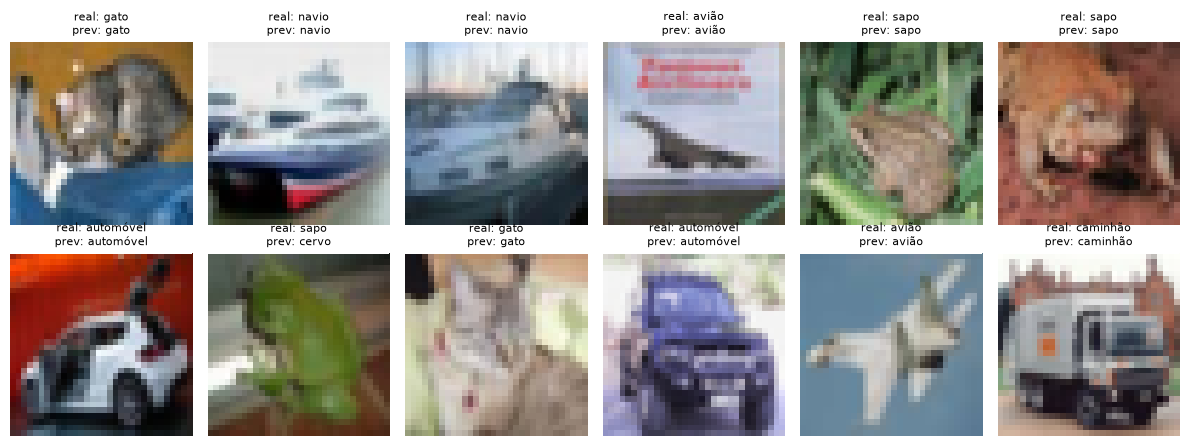

In [7]:
probs = model.predict(X_test[:12], verbose=0)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, img, prob, true in zip(axes.ravel(), X_test[:12], probs, y_test[:12]):
    ax.imshow(img)
    ax.set_title(f"real: {CLASSES[true]}\nprev: {CLASSES[prob.argmax()]}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()